In [1]:
%pip install reservoirpy

#Referencia para la instalación:
#Nathan Trouvain, Luca Pedrelli, Thanh Trung Dinh, Xavier Hinaut. ReservoirPy: an Efficient and User-Friendly Library to Design Echo State Networks. 2020. ⟨hal-02595026⟩ https://hal.inria.fr/hal-02595026

In [2]:
import reservoirpy as rpy
from reservoirpy.nodes import Reservoir
#reservoirpy.hyper para automatizar la busqueda de los mejores parametros
rpy.set_seed(42)
#reservoir = Reservoir()

In [3]:
#PArte 1 : datos simulados
#usando lorenz 96 su ec.diferencial


#solucion por runge kuta 4
import numpy as np
import os

# parte 1: datos simulados con lorenz 96, resuelto con runge kutta 4
#esto para definir
def lorenz96(x, F):
    # dx_j/dt = (x_{j+1} - x_{j-2}) * x_{j-1} - x_j + F
    Q = len(x)
    dx = np.zeros(Q)
    for j in range(Q):
        # indices modulo Q -> frontera periodica
        dx[j] = (x[(j+1) % Q] - x[(j-2) % Q]) * x[(j-1) % Q] - x[j] + F
    return dx

def paso_rk4(x, F, dt):
    k1 = lorenz96(x, F)
    k2 = lorenz96(x + 0.5*dt*k1, F)
    k3 = lorenz96(x + 0.5*dt*k2, F)
    k4 = lorenz96(x + dt*k3, F)
    return x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

def generar_datos(Q=36, F=8.0, dt=0.01, pasos_guardados=20000, cada=5, transitorio=5000):
  # condicion inicial: todo en F y una perturbacion  en x_0 pARA QUE SEA CAHOTIIC
    x = F*np.ones(Q)
    x[0] += 0.01

    # descartamos el transitorio (los datos del inicio pues que se ven muy afectados por las condiciones iniciales que deberian ser arbitrarias)
    for i in range(transitorio):
        x = paso_rk4(x, F, dt)

    # filas = tiempo, columnas = variables
    U = np.zeros((pasos_guardados, Q))
    fila = 0
    paso = 0
    while fila < pasos_guardados:
        x = paso_rk4(x, F, dt)
        if paso % cada == 0:      # guardamos 1 de cada 'cada' pasosss
            U[fila] = x
            fila += 1
        paso += 1

    return U

U = generar_datos()
print("Forma de los datos (tiempo, variables):", U.shape)
print("Primeras 2 filas:\n", U[:2])
#crear la super carpeta de los datoos
os.makedirs("datos", exist_ok=True)
np.save("datos/lorenz96.npy", U)
print("Guardado en datos/lorenz96.npy")

Forma de los datos (tiempo, variables): (20000, 36)
Primeras 2 filas:
 [[-0.72552264  2.46472299  2.60883472  5.45255529  1.74731621 -2.37615039
   0.64781479  8.70511315  0.28256157 -3.43517844  2.86822872  6.73450659
   2.5924355   4.30623275  4.48957027 -3.56568276  1.46102138  2.08373188
   8.02555054 -0.7573825  -1.05184529  1.23361959 11.73920185  0.9242563
  -3.12329854  1.65634572  5.60604995 -0.86357717 -2.52971346  0.93004597
   5.80407296  9.27354826 -0.74485182 -7.00972019  0.02183535  8.62157974]
 [ 1.40011479  2.68229973  3.53175745  5.35580666  0.6273682  -2.16005962
   0.16795516  8.71226538 -0.84413049 -2.77153233  1.98131926  7.52128444
   3.47426206  4.00056155  3.32244208 -3.46651724  1.98718824  3.35209442
   7.62759824 -1.61691273 -0.22402033  1.1561396  11.58827876 -1.03969725
  -2.52276129  1.14342417  5.84380594 -1.42154413 -1.726385    0.52277466
   6.29064089  8.01817897 -5.48787493 -4.59429499 -2.98773587  8.13087605]]
Guardado en datos/lorenz96.npy


In [17]:
# ======================================================================
#  ENTRENAMIENTO ESN  —  readout sobre [r ; r^2]  (fiel a Pathak et al.)
# ======================================================================
from reservoirpy.nodes import Reservoir, Ridge
from reservoirpy.observables import nrmse
import matplotlib.pyplot as plt
import numpy as np

# ---------- Datos ----------
U = np.load("datos/lorenz96.npy")        # (20000, 36)
n_train = 15000
U_train = U[:n_train]
U_test  = U[n_train:]

media = U_train.mean(axis=0)
std   = U_train.std(axis=0)
U_train_norm = (U_train - media) / std
U_test_norm  = (U_test  - media) / std

# Entrada con ruido (estabiliza la realimentacion autonoma), objetivo limpio
noise_amp = 0.05
X_train = U_train_norm[:-1] + noise_amp * np.random.default_rng(42).standard_normal(U_train_norm[:-1].shape)
Y_train = U_train_norm[1:]

# ---------- Reservoir ----------
reservoir = Reservoir(
    units=2000,
    lr=0.9,
    sr=0.6,
    input_scaling=0.1,
    input_connectivity=0.1,
    rc_connectivity=0.05,
    seed=42,
)
readout = Ridge(ridge=1.0)              # regularizacion mas fuerte para [r ; r^2]

# ---------- ENTRENAMIENTO: armar [r ; r^2] y entrenar solo la salida ----------
R = reservoir.run(X_train)                       # estados r(t), forma (n, N)
R_feat = np.concatenate([R, R**2], axis=1)       # [r ; r^2]  (cuadrados PUROS, sin cruzados)
print("Dimension de caracteristicas:", R_feat.shape)   # (n, 2N) = (n, 4000)

warmup = 100
readout.fit(R_feat[warmup:], Y_train[warmup:])

# diagnostico: error a UN paso (sin realimentacion)
Y_onestep = readout.run(R_feat)
print(f"NRMSE 1-paso (norm): {nrmse(Y_train, Y_onestep):.4f}")

# ---------- PREDICCION autonoma ----------
reservoir.reset()
step_warmup    = 150
step_prediccion = 300

R_wu = reservoir.run(U_test_norm[:step_warmup])  # sincroniza el estado con datos reales
r_actual = np.asarray(R_wu[-1]).ravel()
u_actual = readout.run(np.concatenate([r_actual, r_actual**2]).reshape(1, -1)).ravel()

predicciones_norm = np.zeros((step_prediccion, U.shape[1]))
predicciones_norm[0] = u_actual

for t in range(1, step_prediccion):
    R_step = reservoir.run(u_actual.reshape(1, -1))      # avanza un paso con su propia prediccion
    r_actual = np.asarray(R_step[-1]).ravel()
    u_actual = readout.run(np.concatenate([r_actual, r_actual**2]).reshape(1, -1)).ravel()
    predicciones_norm[t] = u_actual

Y_pred = predicciones_norm * std + media          # desnormalizar para graficar
Y_real = U_test[step_warmup : step_warmup + step_prediccion]

# ======================================================================
#  CRITERIO DE VALIDACION  (tiempo de Lyapunov)
# ======================================================================
dt_datos   = 0.05                    # Δt entre filas (dt=0.01 * cada=5)
lambda_max = 1.67                    # exponente de Lyapunov maximo (Lorenz-96, F=8, N=36)
t_lyapunov = 1.0 / lambda_max        # ≈ 0.599 u.t.

Y_true_norm = U_test_norm[step_warmup : step_warmup + step_prediccion]
err_t = np.sqrt(((predicciones_norm - Y_true_norm)**2).mean(axis=1))

umbral = 0.3
cruce = np.argmax(err_t > umbral) if np.any(err_t > umbral) else step_prediccion
t_valido_ut   = cruce * dt_datos
t_valido_lyap = t_valido_ut / t_lyapunov

print(f"Prediccion valida: {cruce} pasos = {t_valido_ut:.2f} u.t. = {t_valido_lyap:.2f} tiempos de Lyapunov")


Dimension de caracteristicas: (14999, 4000)
NRMSE 1-paso (norm): 0.0083
Prediccion valida: 5 pasos = 0.25 u.t. = 0.42 tiempos de Lyapunov


Error Normalizado: 0.2411


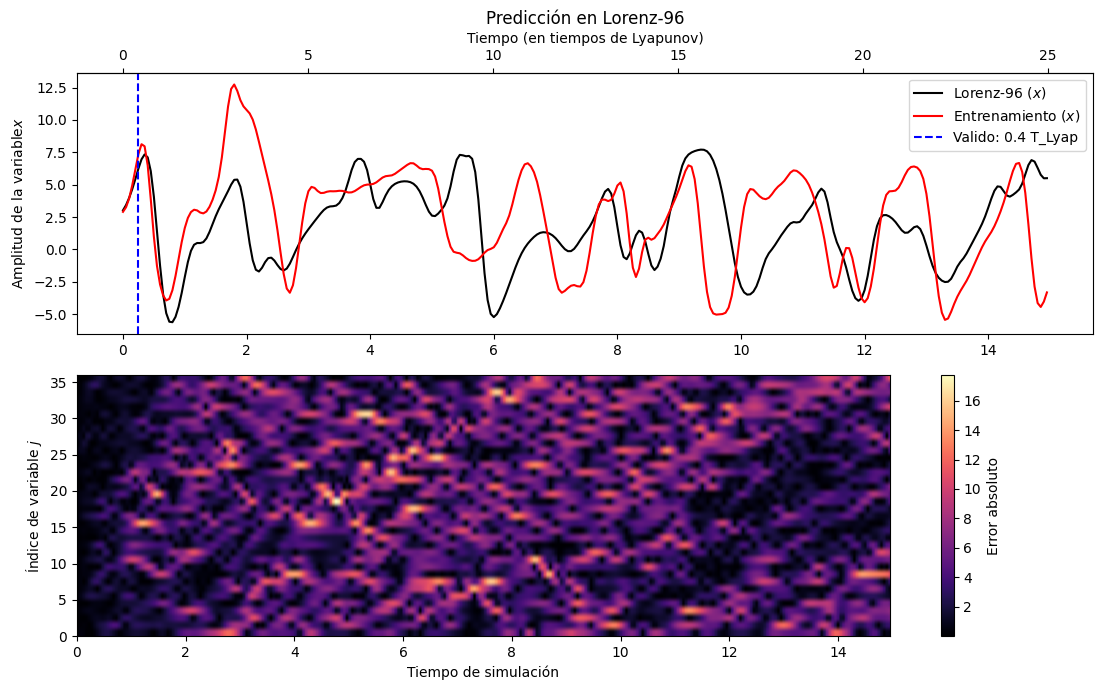

In [19]:
tiempo = np.arange(step_prediccion) * 0.05
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

#Predicción para una variable, puede verse de 0 a 35
axes[0].plot(tiempo, Y_real[:, 11], label="Lorenz-96 ($x$)", color="black")
axes[0].plot(tiempo, Y_pred[:, 11], label="Entrenamiento ($x$)", color="red")
axes[0].set_ylabel("Amplitud de la variable$x$")
axes[0].set_title("Predicción en Lorenz-96")
axes[0].legend()

axes[0].axvline(t_valido_ut, color="blue", ls="--",
                label=f"Valido: {t_valido_lyap:.1f} T_Lyap")
axes[0].legend()   # vuelve a llamarlo para que aparezca la linea azul
secax = axes[0].secondary_xaxis('top',
    functions=(lambda t: t / t_lyapunov, lambda l: l * t_lyapunov))
secax.set_xlabel("Tiempo (en tiempos de Lyapunov)")


print(f"Error Normalizado: {nrmse(Y_real[:], Y_pred[:]):.4f}")
#Error para todas las variables en cada paso de tiempo
error_abs = np.abs(Y_real - Y_pred).T
im = axes[1].imshow(error_abs, aspect="auto", origin="lower",
                    extent=[tiempo[0], tiempo[-1], 0, U.shape[1]], cmap="magma")
axes[1].set_ylabel("Índice de variable $j$")
axes[1].set_xlabel("Tiempo de simulación")
fig.colorbar(im, ax=axes[1], label="Error absoluto")

plt.tight_layout()
plt.savefig("prediccion_lorenz96.png")
plt.show()

In [36]:
# ======================================================================
#  CELDA 1 — ESN PARALELO: entrenamiento + validacion (imprime horizonte t)
# ======================================================================
from reservoirpy.nodes import Reservoir, Ridge
import numpy as np

# ---------- Arquitectura y hiperparametros ganadores ----------
Q            = U.shape[1]        # 36 variables
n_grupos     = 18               # 18 grupos de 2 variables
tam_grupo    = Q // n_grupos
solape       = 2                # minimo para capturar el acoplamiento de Lorenz-96

units_g       = 600
lr, sr        = 1.0, 0.4
input_scaling = 0.15
ridge_val     = 1e-6
noise_amp     = 0.005
seed          = 42

# ---------- Parametros fisicos ----------
dt_datos   = 0.05               # Δt efectivo (dt=0.01 * cada=5)
lambda_max = 1.67               # exponente de Lyapunov maximo (Lorenz-96, F=8, N=36)
t_lyapunov = 1.0 / lambda_max   # ≈ 0.599 u.t.

# ---------- Indices de cada grupo (frontera periodica) ----------
centros  = [np.arange(g*tam_grupo, (g+1)*tam_grupo) for g in range(n_grupos)]
entradas = [np.arange(g*tam_grupo - solape, (g+1)*tam_grupo + solape) % Q
            for g in range(n_grupos)]

# ---------- Entrenamiento: un reservoir + readout [r ; r^2] por grupo ----------
rng = np.random.default_rng(seed)
Xtr = U_train_norm[:-1] + noise_amp * rng.standard_normal(U_train_norm[:-1].shape)
Ytr = U_train_norm[1:]

reservoirs, readouts = [], []
for g in range(n_grupos):
    res = Reservoir(units=units_g, lr=lr, sr=sr, input_scaling=input_scaling,
                    input_connectivity=0.1, rc_connectivity=0.05, seed=seed + g)
    rd  = Ridge(ridge=ridge_val)
    R   = res.run(Xtr[:, entradas[g]])              # entrada = centrales + solape
    Rf  = np.concatenate([R, R**2], axis=1)         # [r ; r^2] (cuadrados puros)
    rd.fit(Rf[100:], Ytr[100:, centros[g]])         # objetivo = solo las centrales
    reservoirs.append(res)
    readouts.append(rd)

print(f"Entrenados {n_grupos} reservoirs de {units_g} neuronas "
      f"(entrada {len(entradas[0])}, salida {tam_grupo})")

# ---------- Prediccion autonoma conjunta ----------
def predecir_paralelo(inicio, step_warmup=150, step_prediccion=300):
    for res in reservoirs:
        res.reset()
    estados = [np.asarray(reservoirs[g].run(
                 U_test_norm[inicio - step_warmup : inicio, entradas[g]])[-1]).ravel()
               for g in range(n_grupos)]

    pred = np.zeros((step_prediccion, Q))
    u = np.zeros(Q)
    for g in range(n_grupos):                        # primer paso desde el estado del warmup
        r = estados[g]
        u[centros[g]] = readouts[g].run(np.concatenate([r, r**2]).reshape(1, -1)).ravel()
    pred[0] = u

    for t in range(1, step_prediccion):              # reinyeccion autonoma
        un = np.zeros(Q)
        for g in range(n_grupos):
            r = np.asarray(reservoirs[g].run(u[entradas[g]].reshape(1, -1))[-1]).ravel()
            un[centros[g]] = readouts[g].run(np.concatenate([r, r**2]).reshape(1, -1)).ravel()
        u = un
        pred[t] = u
    return pred

# ---------- Validacion robusta: horizonte promediado sobre 8 ventanas ----------
step_warmup, step_prediccion, umbral = 150, 300, 0.4
n_test = len(U_test_norm)
arranques = np.linspace(step_warmup, n_test - step_prediccion - 1, 8).astype(int)

horizontes = []
for ini in arranques:
    pred = predecir_paralelo(ini, step_warmup, step_prediccion)
    real = U_test_norm[ini : ini + step_prediccion]
    err_t = np.sqrt(((pred - real)**2).mean(axis=1))
    cruce = np.argmax(err_t > umbral) if np.any(err_t > umbral) else step_prediccion
    horizontes.append(cruce)

h = np.array(horizontes) * dt_datos / t_lyapunov
print(f"Horizonte ESN PARALELO: {h.mean():.2f} +/- {h.std():.2f} tiempos de Lyapunov")
print(f"(por ventana: {[f'{x:.2f}' for x in h]})")


Entrenados 18 reservoirs de 600 neuronas (entrada 6, salida 2)
Horizonte ESN PARALELO: 4.16 +/- 0.94 tiempos de Lyapunov
(por ventana: ['4.01', '5.76', '4.26', '4.43', '3.34', '2.34', '4.59', '4.59'])


Ventana graficada: valido hasta 48 pasos = 2.40 u.t. = 4.01 tiempos de Lyapunov


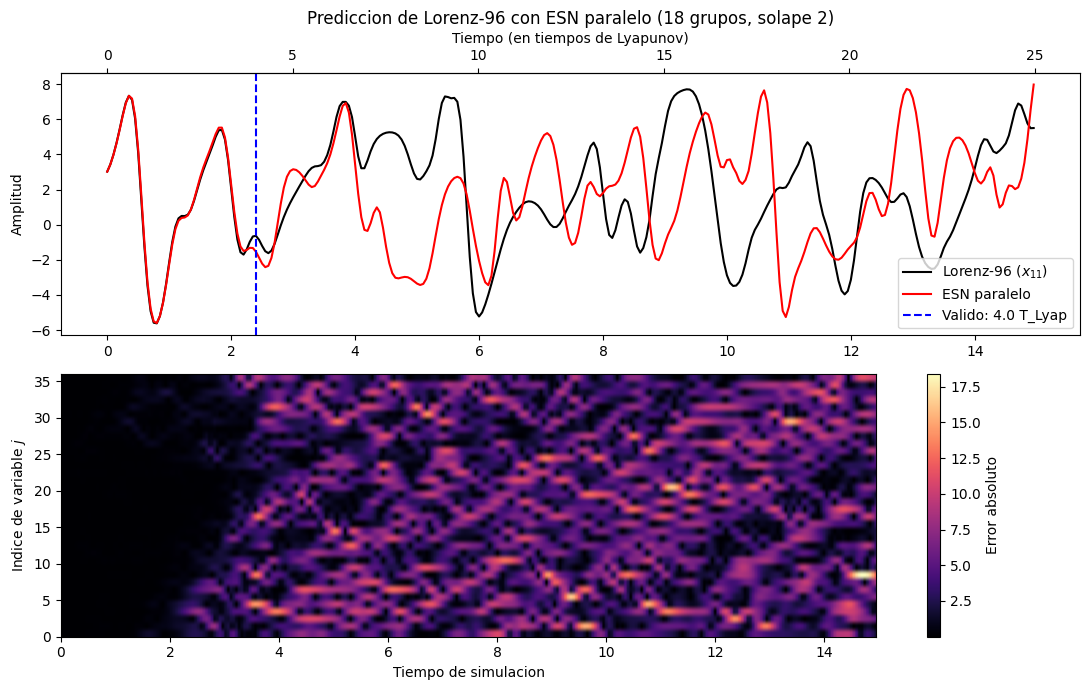

In [37]:
# ======================================================================
#  CELDA 2 — Grafica de una ventana representativa
# ======================================================================
import matplotlib.pyplot as plt
import numpy as np

inicio = arranques[0]
pred_norm = predecir_paralelo(inicio, step_warmup, step_prediccion)
Y_pred = pred_norm * std + media
Y_real = U_test_norm[inicio : inicio + step_prediccion] * std + media

# instante de cruce del umbral para esta ventana
err_t = np.sqrt(((pred_norm - U_test_norm[inicio:inicio+step_prediccion])**2).mean(axis=1))
cruce = np.argmax(err_t > umbral) if np.any(err_t > umbral) else step_prediccion
t_valido_ut   = cruce * dt_datos
t_valido_lyap = t_valido_ut / t_lyapunov
print(f"Ventana graficada: valido hasta {cruce} pasos = "
      f"{t_valido_ut:.2f} u.t. = {t_valido_lyap:.2f} tiempos de Lyapunov")

tiempo = np.arange(step_prediccion) * dt_datos
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

# --- Panel superior: una variable real vs predicha ---
axes[0].plot(tiempo, Y_real[:, 11], color="black", label="Lorenz-96 ($x_{11}$)")
axes[0].plot(tiempo, Y_pred[:, 11], color="red",   label="ESN paralelo")
axes[0].axvline(t_valido_ut, color="blue", ls="--",
                label=f"Valido: {t_valido_lyap:.1f} T_Lyap")
axes[0].set_ylabel("Amplitud")
axes[0].set_title("Prediccion de Lorenz-96 con ESN paralelo (18 grupos, solape 2)")
axes[0].legend()
secax = axes[0].secondary_xaxis('top',
    functions=(lambda t: t / t_lyapunov, lambda l: l * t_lyapunov))
secax.set_xlabel("Tiempo (en tiempos de Lyapunov)")

# --- Panel inferior: mapa de error de las 36 variables ---
error_abs = np.abs(Y_real - Y_pred).T
im = axes[1].imshow(error_abs, aspect="auto", origin="lower",
                    extent=[tiempo[0], tiempo[-1], 0, Q], cmap="magma")
axes[1].set_ylabel("Indice de variable $j$")
axes[1].set_xlabel("Tiempo de simulacion")
fig.colorbar(im, ax=axes[1], label="Error absoluto")

plt.tight_layout()
plt.savefig("prediccion_lorenz96_paralelo.png", dpi=120)
plt.show()

